# Why Do Clinical Trials Stop Early?

**An analysis of 289,595 finished trials from ClinicalTrials.gov (AACT database)**

Author: Prashant Lodhi

---

## Project summary

| | |
|---|---|
| **Dataset** | AACT, a cleaned relational copy of the public ClinicalTrials.gov registry (606,820 registered studies) |
| **Question** | Why do some clinical trials stop early (are *terminated*), and does it depend on trial phase or on who sponsors the trial? |
| **Methods** | Data cleaning in pandas, keyword-based text classification of free-text stop reasons, group comparisons, logistic regression |
| **Tools** | Python (pandas, NumPy, statsmodels, matplotlib) |

### How to read this notebook
I have kept the working steps close to the results: each section gives the question, the code, the output, and a short note on what the output does and does not show.

### Key results
- About **1 in 10** finished interventional trials was terminated (10.3%).
- **Phase matters.** With sponsor, start year, and number of arms held constant, Phase 1/2 (odds ratio 1.85) and Phase 2 (1.52) have the highest odds of termination relative to Phase 3. Trials with no recorded phase have the lowest odds (0.51).
- **Industry sponsorship is not clearly associated with termination after adjustment.** The industry-versus-`OTHER` odds ratio is 1.02 (95% CI 0.99 to 1.05).
- **The stated reasons still differ by sponsor group.** Business and safety labels are more common for industry trials, while enrollment and funding labels are more common for the `OTHER` group (Sections 6–9).
- The model explains very little (pseudo R² = 0.03), so these results are descriptive, not predictive.

## How to run this notebook

1. Download the monthly **pipe-delimited flat files** from the [AACT download page](https://aact.ctti-clinicaltrials.org/downloads) and unzip them.
2. Put the files in `data` (so that `data/studies.txt` exists), or set the environment variable `AACT_DIR` to the folder.
3. Install the requirements: `pip install -r requirements.txt`
4. Choose **Kernel > Restart & Run All**.

The data files are large and are **not** stored in this repository. Add the snapshot month you downloaded here: `AACT snapshot: ____`.

## 0. Setup

In [35]:
import os
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

DATA_DIR = Path(os.environ.get("AACT_DIR", "data"))

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 80)

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})

## 1. What does the dataset look like?

**Question:** How many trials are in the file, and what statuses do they have?

Each row of `studies.txt` is one registered study. `overall_status` says whether the study is completed, still recruiting, terminated, and so on.

In [36]:
studies = pd.read_csv(DATA_DIR / "studies.txt", sep="|", low_memory=False)
print(studies.shape)

(606820, 71)


In [37]:
print(studies["overall_status"].value_counts())

overall_status
COMPLETED                    331738
UNKNOWN                       97997
RECRUITING                    64709
TERMINATED                    34472
NOT_YET_RECRUITING            29884
ACTIVE_NOT_RECRUITING         22077
WITHDRAWN                     16868
ENROLLING_BY_INVITATION        5245
SUSPENDED                      1774
WITHHELD                        985
NO_LONGER_AVAILABLE             538
AVAILABLE                       253
APPROVED_FOR_MARKETING          244
TEMPORARILY_NOT_AVAILABLE        36
Name: count, dtype: int64


**Interpretation:** There are 606,820 studies. Most are `COMPLETED`, and 34,472 are `TERMINATED` (stopped early). `WITHDRAWN` studies never enrolled anyone, so they are a different situation and are not part of the comparison.

## 2. Which trials do we analyse?

**Question:** What share of finished trials ended early?

I keep only **interventional** studies (trials that test a treatment) whose outcome is known: `COMPLETED` or `TERMINATED`. Studies that are still running or have an unknown status cannot tell us whether a trial finished or stopped.

The `phase` column is empty for trials where phases do not apply (for example behavioural or device studies), so I label those `"NA"` instead of silently dropping them.

In [38]:
df = studies[
    (studies["study_type"] == "INTERVENTIONAL")
    & (studies["overall_status"].isin(["COMPLETED", "TERMINATED"]))
].copy()

df["terminated"] = (df["overall_status"] == "TERMINATED").astype(int)
df["phase"] = df["phase"].fillna("NA")

print(df.shape, df["terminated"].mean())

(289595, 72) 0.10333396640135362


**Interpretation:** 289,595 trials remain, and **10.3%** of them were terminated.

## 3. Does the termination rate differ by phase or sponsor?

**Question:** Are some phases or sponsor types stopped early more often than others?

Trials of drugs run in phases: Phase 1 (small safety tests), Phase 2 (early tests of effect), Phase 3 (large confirmation trials), Phase 4 (after approval). `source_class` is the type of sponsor.

In [39]:
print(df.groupby("phase")["terminated"].agg(["count", "mean"]))

                count      mean
phase                          
EARLY_PHASE1     3116  0.136072
NA             140636  0.066704
PHASE1          36729  0.108198
PHASE1/PHASE2    9475  0.208338
PHASE2          41509  0.175504
PHASE2/PHASE3    4495  0.147942
PHASE3          29717  0.118316
PHASE4          23918  0.113137


In [40]:
print(df.groupby("source_class")["terminated"].agg(["count", "mean"]))

               count      mean
source_class                  
FED             3241  0.078062
INDIV            295  0.115254
INDUSTRY       86449  0.123044
NETWORK         2390  0.135983
NIH             7108  0.107907
OTHER         184382  0.095492
OTHER_GOV       5536  0.052204
UNKNOWN          194  0.067010


**Interpretation:** The raw rates vary by both phase and sponsor group. Phase 1/2 and Phase 2 have the highest observed termination rates. Industry is also higher than `OTHER` (12.3% versus 9.5%), but this is not an adjusted comparison: the two groups have different mixes of phases. The regression in Section 10 considers phase, year, and number of arms together.

## 4. What reasons do sponsors give when a trial stops?

**Question:** What does the free-text `why_stopped` column look like?

In [41]:
term = df[df["terminated"] == 1].copy()

print(f"Terminated trials: {len(term):,}")
print(f"Share with no reason given: {term['why_stopped'].isna().mean():.1%}")
print()
print(term["why_stopped"].value_counts().head(15))

Terminated trials: 29,925
Share with no reason given: 10.0%

why_stopped
Sponsor decision                                   229
Slow accrual                                       229
Low accrual                                        145
Sponsor Decision                                   130
Lack of enrollment                                 120
See termination reason in detailed description.    117
slow accrual                                       116
low accrual                                        116
Slow enrollment                                    107
Low enrollment                                     105
Lack of funding                                    104
Slow recruitment                                    98
Poor accrual                                        90
Business decision                                   86
Slow Accrual                                        83
Name: count, dtype: int64


**Interpretation:** The reasons are typed in freely, so the same idea appears in many wordings ("slow accrual", "low accrual", "poor inclusion", ...). Counting the raw text would split one reason into dozens of tiny groups. About one in ten terminated trials gives no reason at all. To analyse reasons I first need to group them.

## 5. Grouping the free-text reasons into categories

**Question:** Can the reasons be sorted into a small set of meaningful categories?

I wrote keyword rules, checked in order (the **first match wins**), and refined them over several passes by reading random samples of unmatched reasons.

A few choices in the rules are worth spelling out:
- `COVID-19` is checked first because it is a distinct outside cause.
- `Enrollment` is checked **before** `Efficacy/futility`, because phrases like "insufficient enrollment" would otherwise be misread as lack of efficacy.
- Short stems that could appear inside other words use `\b` (word start). For example `\bharm` is used instead of `harm`, which would wrongly match "p**harm**aceutical".
- Each trial gets **one** label, which is a simplification: "low enrollment and funding loss" is filed under the first matching rule.

In [42]:
rules = [
    ("COVID-19", r"covid|pandemic"),
    ("Safety", r"safety|toxic|adverse|death|mortality|reactogenicity|halting criteria|side effect|\bharm"),
    ("Enrollment", r"accrual|enroll|recruit|inclusion|low number|too few|poor participation|insufficient (number|patient|subject|participant)"),
    ("Efficacy/futility", r"futil|efficacy|insufficient (effect|activity|benefit)|no (significant )?(difference|effect|benefit)|did not (meet|demonstrate|show)|ineffective|lack of (effect|benefit)|primary (outcome|endpoint)|interim|preliminary results"),
    ("Drug supply", r"supply|unavailable|no longer available|recall|shelf|manufactur|expired"),
    ("Regulatory", r"\bfda\b|\bema\b|regulatory|ethic|\birb\b|approval"),
    ("Funding", r"\bfund(s|ed|ing)?\b|financ|budget|cost|\bgrant"),
    ("Sponsor/business", r"sponsor|business|strategic|compan|portfolio|commercial|priorit"),
    ("Design/feasibility", r"\bdesign|protocol|amend|modif|sample size|feasib|methodolog|supersed"),
    ("Staff/investigator", r"investigator|\bpi\b|cancel|relocat|left the|retire|\bmoved|surgeon|staff|personnel|\bresident"),
]


def categorize(reason):
    """Return the first matching category for a free-text stop reason."""
    r = str(reason).lower().strip()
    if r in ("", "nan") or "see termination reason" in r:
        return "Not given"
    for name, pattern in rules:
        if re.search(pattern, r):
            return name
    return "Other"


term["category"] = term["why_stopped"].apply(categorize)
print(term["category"].value_counts(normalize=True).round(3))

category
Enrollment            0.332
Other                 0.163
Not given             0.104
Sponsor/business      0.091
Safety                0.068
Efficacy/futility     0.059
COVID-19              0.049
Funding               0.048
Staff/investigator    0.037
Design/feasibility    0.019
Drug supply           0.016
Regulatory            0.014
Name: proportion, dtype: float64


**Interpretation:** Enrollment is the largest named category. `Other` still accounts for about 16% of records, so the labels should be read as a broad summary rather than a complete account of every reason given.

### Checking the classifier

A rule-based classifier makes mistakes, so I check a random sample by eye.

In [43]:
for cat in ["Enrollment", "Efficacy/futility", "Safety", "Sponsor/business"]:
    print(f"\n===== {cat}")
    print(term.loc[term["category"] == cat, "why_stopped"].sample(25, random_state=3).to_string())


===== Enrollment
407021                              Low study accrual caused the study to be ended early.
305101                          Difficulty enrolling patients due to enrollment criteria.
404750                                      Study was terminated prior to full enrollment
585455                                        Study was terminated due to low enrollment.
210929                                                                        low accrual
93850          The study was stopped solely based on lower than expected enrollment rate.
436560                                                                        low accrual
532662                                                                        Low accrual
497672                                                  Not enough interest in enrollment
54916                                        The recruitment of subject is very difficult
320912                                                                inclusions p

**Sample check result**

| Category | Correct out of 25 |
|---|---|
| Enrollment | 25 / 25 |
| Efficacy/futility | 22 / 25 |
| Safety | 8 / 25 |
| Sponsor/business | 25 / 25 |

Reporting how accurate the labels are is part of being honest about what the method can and cannot show.

## 6. Do the reasons differ by phase?

**Question:** For terminated trials in each phase, what share was stopped for each reason?

Each row below adds up to 1 (100%).

In [44]:
print(pd.crosstab(term["phase"], term["category"], normalize="index").round(2))

category       COVID-19  Design/feasibility  Drug supply  Efficacy/futility  Enrollment  Funding  Not given  Other  Regulatory  Safety  Sponsor/business  Staff/investigator
phase                                                                                                                                                                       
EARLY_PHASE1       0.06                0.02         0.05               0.03        0.32     0.10       0.05   0.18        0.02    0.03              0.06                0.08
NA                 0.10                0.03         0.01               0.03        0.39     0.06       0.06   0.18        0.02    0.02              0.04                0.06
PHASE1             0.02                0.01         0.02               0.04        0.20     0.04       0.14   0.17        0.01    0.11              0.20                0.02
PHASE1/PHASE2      0.02                0.02         0.02               0.06        0.24     0.05       0.10   0.17        0.01    0.11 

**Interpretation:** The table is descriptive. Differences across phases may reflect what the trial was designed to test, but the smaller groups—especially Early Phase 1—should be interpreted cautiously.

## 7. Do the reasons differ by sponsor type?

**Question:** For terminated trials of each sponsor type, what share was stopped for each reason?

Each column adds up to 1. The group sizes are printed below the table because small groups (for example `INDIV` and `UNKNOWN`) give unreliable percentages.

In [45]:
print(pd.crosstab(term["source_class"], term["category"], normalize="index").round(2).T)
print()
print(term["source_class"].value_counts())

source_class         FED  INDIV  INDUSTRY  NETWORK   NIH  OTHER  OTHER_GOV  UNKNOWN
category                                                                           
COVID-19            0.10   0.00      0.02     0.01  0.02   0.07       0.08     0.00
Design/feasibility  0.04   0.00      0.02     0.01  0.01   0.02       0.03     0.00
Drug supply         0.02   0.00      0.01     0.02  0.05   0.02       0.00     0.00
Efficacy/futility   0.02   0.03      0.09     0.04  0.06   0.04       0.06     0.08
Enrollment          0.37   0.53      0.18     0.56  0.29   0.42       0.35     0.31
Funding             0.09   0.06      0.01     0.02  0.01   0.07       0.02     0.00
Not given           0.06   0.03      0.15     0.16  0.33   0.07       0.17     0.23
Other               0.14   0.18      0.16     0.11  0.16   0.16       0.20     0.15
Regulatory          0.02   0.03      0.02     0.00  0.00   0.01       0.02     0.00
Safety              0.02   0.03      0.14     0.04  0.04   0.03       0.02  

**Interpretation:** The clearest comparison is between `INDUSTRY` and `OTHER`, because those are the two largest groups. Percentages for the smaller groups are included for completeness but are less stable.

## 8. Does the sponsor pattern hold within the same phase?

**Question:** `INDUSTRY` and `OTHER` trials have different mixes of phases. Do the reason patterns remain when trials in the same phase are compared?

I compare Phase 2 and Phase 3 separately, for `INDUSTRY` vs `OTHER` sponsors.

In [46]:
sub_terminated = term[
    term["phase"].isin(["PHASE2", "PHASE3"]) & term["source_class"].isin(["INDUSTRY", "OTHER"])
]

print(sub_terminated.groupby(["phase", "source_class"]).size())
print()
print(
    pd.crosstab(
        sub_terminated["category"],
        [sub_terminated["phase"], sub_terminated["source_class"]],
        normalize="columns",
    ).round(2)
)

phase   source_class
PHASE2  INDUSTRY        2936
        OTHER           3800
PHASE3  INDUSTRY        2043
        OTHER           1266
dtype: int64

phase                PHASE2         PHASE3      
source_class       INDUSTRY OTHER INDUSTRY OTHER
category                                        
COVID-19               0.02  0.04     0.01  0.03
Design/feasibility     0.01  0.01     0.01  0.02
Drug supply            0.00  0.02     0.00  0.01
Efficacy/futility      0.12  0.06     0.15  0.09
Enrollment             0.18  0.48     0.14  0.45
Funding                0.01  0.07     0.00  0.04
Not given              0.17  0.06     0.18  0.11
Other                  0.15  0.14     0.15  0.16
Regulatory             0.01  0.01     0.03  0.01
Safety                 0.14  0.04     0.16  0.04
Sponsor/business       0.19  0.03     0.17  0.02
Staff/investigator     0.00  0.04     0.00  0.03


**Interpretation:** Similar differences in both phases would suggest that phase mix is not the whole explanation. They would not, however, rule out other differences between the sponsor groups.

**Important caveat:** these are shares *among terminated trials*, so they always add up to 100%. A larger share for one reason necessarily leaves less room for the others. Section 9 uses all completed and terminated trials as the denominator instead.

## 9. How common is each reason, per 100 finished trials?

**Question:** Out of every 100 finished trials of a given type, how many stopped for each reason?

Using **all finished trials** (completed and terminated) as the denominator gives real rates that can be compared between groups.

In [47]:
df["category"] = "Completed"
df.loc[term.index, "category"] = term["category"]

sub = df[df["phase"].isin(["PHASE2", "PHASE3"]) & df["source_class"].isin(["INDUSTRY", "OTHER"])]

rates = (
    pd.crosstab(sub["category"], [sub["phase"], sub["source_class"]], normalize="columns") * 100
)

print("Trials stopped for each reason, per 100 finished trials")
print(rates.drop("Completed").round(1))
print()
print("Completed, per 100 finished trials")
print(rates.loc["Completed"].round(1))

Trials stopped for each reason, per 100 finished trials
phase                PHASE2         PHASE3      
source_class       INDUSTRY OTHER INDUSTRY OTHER
category                                        
COVID-19                0.4   0.7      0.1   0.5
Design/feasibility      0.2   0.2      0.1   0.2
Drug supply             0.1   0.5      0.0   0.2
Efficacy/futility       1.9   1.1      1.6   1.2
Enrollment              3.0   9.2      1.5   6.1
Funding                 0.2   1.3      0.0   0.6
Not given               2.8   1.2      2.0   1.5
Other                   2.4   2.7      1.7   2.2
Regulatory              0.2   0.2      0.3   0.1
Safety                  2.4   0.8      1.8   0.6
Sponsor/business        3.1   0.6      1.8   0.2
Staff/investigator      0.0   0.9      0.0   0.4

Completed, per 100 finished trials
phase   source_class
PHASE2  INDUSTRY        83.3
        OTHER           80.6
PHASE3  INDUSTRY        88.9
        OTHER           86.4
Name: Completed, dtype: float64


**Interpretation:** These rates answer a different question from the shares in Section 8. A group can have a smaller share of a given reason among its terminated trials while still having a higher rate of that reason across all finished trials.

### Chart

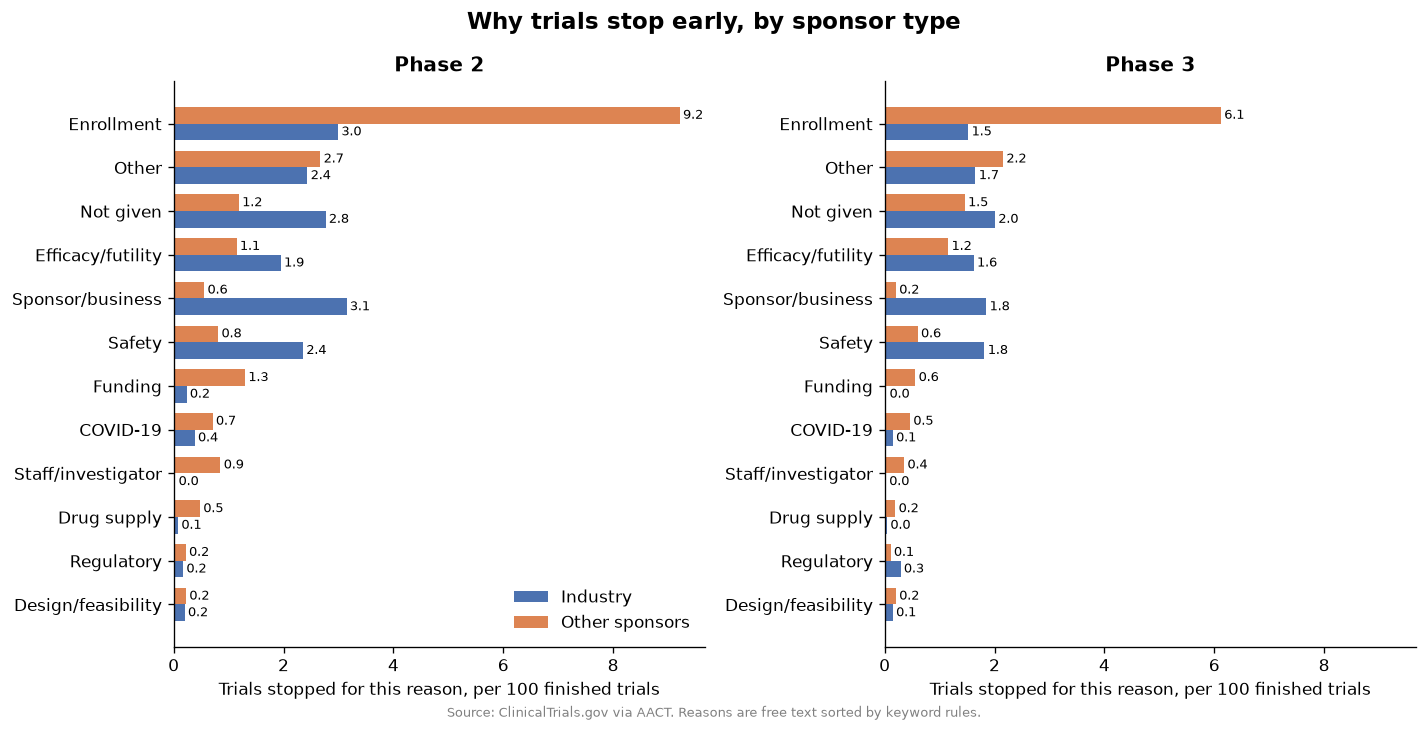

In [48]:
plot_rates = rates.drop("Completed")
order = plot_rates.sum(axis=1).sort_values().index  # smallest to largest

fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharex=True)
bar_h = 0.38

for ax, phase, title in zip(axes, ["PHASE2", "PHASE3"], ["Phase 2", "Phase 3"]):
    data = plot_rates[phase].loc[order]
    y = np.arange(len(data))
    b1 = ax.barh(y - bar_h / 2, data["INDUSTRY"], bar_h, label="Industry", color="#4C72B0")
    b2 = ax.barh(y + bar_h / 2, data["OTHER"], bar_h, label="Other sponsors", color="#DD8452")
    ax.bar_label(b1, fmt="%.1f", padding=2, fontsize=8)
    ax.bar_label(b2, fmt="%.1f", padding=2, fontsize=8)
    ax.set_yticks(y)
    ax.set_yticklabels(data.index)
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Trials stopped for this reason, per 100 finished trials")

axes[0].legend(loc="lower right", frameon=False)
fig.suptitle("Why trials stop early, by sponsor type", fontsize=14, fontweight="bold")
fig.text(0.5, 0.0, "Source: ClinicalTrials.gov via AACT. Reasons are free text sorted by keyword rules.",
         ha="center", fontsize=8, color="gray")
plt.tight_layout()

os.makedirs("images", exist_ok=True)
plt.savefig("images/stop_reasons_per_100_trials.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Which factors matter when held together? (logistic regression)

**Question:** Once phase, sponsor type, start year and number of arms are considered **together**, which of them is still linked to early termination?

**Method:** logistic regression with `terminated` (1 or 0) as the outcome. Results are shown as **odds ratios**:
- 1.0 means no effect,
- above 1 means higher odds of termination than the reference group,
- below 1 means lower odds.

**Choices made:**
- Reference groups are Phase 3 and `OTHER` sponsors.
- `enrollment` is **not** used as a predictor, because terminated trials enroll fewer people *because* they stopped (the cause would run backwards).
- Start years are limited to 2005 to 2022: older records are patchier, and very recent trials that have already finished skew toward short ones.
- Trials with a missing number of arms are dropped, and arms are capped at 6.

In [49]:
m = df.copy()
m["start_year"] = pd.to_datetime(m["start_date"], errors="coerce").dt.year
m = m[m["start_year"].between(2005, 2022)]
print("After year filter:", len(m))

m = m.dropna(subset=["number_of_arms"])
m["number_of_arms"] = m["number_of_arms"].clip(upper=6)
m["sponsor"] = m["source_class"].where(
    m["source_class"].isin(["INDUSTRY", "OTHER", "NIH", "FED", "NETWORK", "OTHER_GOV"]), "OTHER"
)
print("After dropping missing arms:", len(m))
print(m.shape)

After year filter: 233219
After dropping missing arms: 225963
(225963, 75)


The two counts show how many trials remain after the year restriction and after removing records without an arm count.

In [50]:
model = smf.logit(
    "terminated ~ C(phase, Treatment('PHASE3')) + C(sponsor, Treatment('OTHER')) + start_year + number_of_arms",
    data=m,
).fit(disp=False)

print(f"Observations: {int(model.nobs):,}")
print(f"Pseudo R-squared: {model.prsquared:.4f}")
print()

odds = pd.DataFrame({
    "OR": np.exp(model.params),
    "low": np.exp(model.conf_int()[0]),
    "high": np.exp(model.conf_int()[1]),
    "p": model.pvalues,
}).round(3)
odds.index = odds.index.str.replace(r"C\((\w+), Treatment\('\w+'\)\)", r"\1", regex=True)
print(odds.drop("Intercept").to_string())

Observations: 225,963
Pseudo R-squared: 0.0315

                           OR    low   high      p
phase[T.EARLY_PHASE1]   0.973  0.864  1.096  0.655
phase[T.NA]             0.505  0.481  0.530  0.000
phase[T.PHASE1]         0.848  0.804  0.895  0.000
phase[T.PHASE1/PHASE2]  1.848  1.727  1.978  0.000
phase[T.PHASE2]         1.524  1.451  1.600  0.000
phase[T.PHASE2/PHASE3]  1.206  1.091  1.333  0.000
phase[T.PHASE4]         0.907  0.855  0.964  0.002
sponsor[T.FED]          0.958  0.833  1.102  0.550
sponsor[T.INDUSTRY]     1.021  0.989  1.054  0.205
sponsor[T.NETWORK]      1.002  0.857  1.172  0.978
sponsor[T.NIH]          1.179  1.065  1.306  0.002
sponsor[T.OTHER_GOV]    0.500  0.437  0.572  0.000
start_year              1.015  1.013  1.018  0.000
number_of_arms          0.865  0.854  0.877  0.000


### Reading the odds ratios

Compared with Phase 3 (holding sponsor, start year and arms equal):

| Phase | Odds ratio | 95% CI | Meaning |
|---|---|---|---|
| Phase 1/2 | 1.85 | 1.73 to 1.98 | highest odds of early termination |
| Phase 2 | 1.52 | 1.45 to 1.60 | clearly higher |
| Phase 2/3 | 1.21 | 1.09 to 1.33 | modestly higher |
| Phase 4 | 0.91 | 0.86 to 0.96 | slightly lower |
| Phase 1 | 0.85 | 0.80 to 0.90 | lower |
| Early Phase 1 | 0.97 | 0.86 to 1.10 | no clear difference |
| No recorded phase | 0.51 | 0.48 to 0.53 | about half the odds |

Compared with `OTHER` sponsors:
- **Industry: 1.02 (0.99 to 1.05, p = 0.21).** After adjustment for phase, year, and arms, the data do not show a clear difference from `OTHER`. The raw-rate gap becomes much smaller after adjustment, although this model cannot assign that change to phase alone.
- NIH: 1.18 (1.07 to 1.31), slightly higher. Other government: 0.50 (0.44 to 0.57), about half. Federal and network sponsors are not clearly different from `OTHER` in this model. These are smaller groups, so their estimates deserve caution.

Other terms:
- `start_year` 1.015 per year and `number_of_arms` 0.87 per arm are associations, not causal effects. The start-year coefficient is especially difficult to interpret because recently started trials that have already finished tend to be shorter.
- **Pseudo R² = 0.03.** These four factors explain very little of which trials stop early. Termination depends mostly on things this dataset does not capture (the disease, how the treatment performed, money, trial management). The model describes associations; it cannot predict an individual trial.

## 11. Conclusions

1. About **10%** of finished interventional trials on ClinicalTrials.gov were terminated early.
2. **Phase has the strongest association in this model.** Phase 1/2 and Phase 2 have the highest odds of termination, while trials with no recorded phase have the lowest.
3. **Industry is not clearly different from `OTHER` after adjustment** for phase, year, and number of arms (OR 1.02, 95% CI 0.99 to 1.05). The raw difference should not be interpreted as an industry effect.
4. **The reasons recorded at termination differ between the two large sponsor groups.** Business and safety labels are more common for industry trials, while enrollment and funding labels are more common for `OTHER`. These are recorded reasons, not verified causes.
5. The model explains little (pseudo R² 0.03). Treat the findings as descriptive.

## 12. Limitations

- **Stated reasons are not proven causes.** "Business decision" can be a polite way of saying the results were disappointing.
- **Keyword rules make mistakes**, and each trial gets only one label. See the sample check in Section 5 for accuracy.
- **Observational data.** The results show associations, not causes. Disease area and trial size are not controlled for.
- **`OTHER` is a mixed group.** Check the AACT data dictionary for exactly how `source_class` is defined before describing it as "academic".
- Years are limited to 2005 to 2022 in the model, and trials with missing arm counts were dropped (see the counts in Section 10).
- Small groups (`INDIV`, `UNKNOWN`, Early Phase 1, and the smaller government groups) give unstable percentages.

## 13. Possible next steps

- Build a Power BI dashboard from the cleaned data (phase, sponsor and reasons pages).
- Add disease area (the `conditions` table) to the model.
- Replace keyword rules with a better text classifier and compare accuracy.

---
*Data: ClinicalTrials.gov, via the AACT database (CTTI). Use of the data is subject to the ClinicalTrials.gov terms and conditions.*